# Zomato Exploratory Data Analysis

### Step-01 Installing Dependencies

In [2]:
!pip install seaborn


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


In [3]:
!pip install matplotlib


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip


### Step-02 Importing Required Libraries

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### Step-03 Loading Dataset

In [5]:
df = pd.read_csv("zomato_data.csv")

In [6]:
df

,Restaurant Name,Online_Order,Book_Table,Rate,Votes,Approx_Cost(For Two People),Listed_In(Type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet
...,...,...,...,...,...,...,...
143,Melting Melodies,No,No,3.3/5,0,100,Dining
144,New Indraprasta,No,No,3.3/5,0,150,Dining
145,Anna Kuteera,Yes,No,4.0/5,771,450,Dining
146,Darbar,No,No,3.0/5,98,800,Dining


In [7]:
df.head()

,Restaurant Name,Online_Order,Book_Table,Rate,Votes,Approx_Cost(For Two People),Listed_In(Type)
0,Jalsa,Yes,Yes,4.1/5,775,800,Buffet
1,Spice Elephant,Yes,No,4.1/5,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8/5,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7/5,88,300,Buffet
4,Grand Village,No,No,3.8/5,166,600,Buffet


In [8]:
df.tail()

,Restaurant Name,Online_Order,Book_Table,Rate,Votes,Approx_Cost(For Two People),Listed_In(Type)
143,Melting Melodies,No,No,3.3/5,0,100,Dining
144,New Indraprasta,No,No,3.3/5,0,150,Dining
145,Anna Kuteera,Yes,No,4.0/5,771,450,Dining
146,Darbar,No,No,3.0/5,98,800,Dining
147,Vijayalakshmi,Yes,No,3.9/5,47,200,Dining


In [9]:
df.shape

(148, 7)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   Restaurant Name              148 non-null    str  
 1   Online_Order                 148 non-null    str  
 2   Book_Table                   148 non-null    str  
 3   Rate                         148 non-null    str  
 4   Votes                        148 non-null    int64
 5   Approx_Cost(For Two People)  148 non-null    int64
 6   Listed_In(Type)              148 non-null    str  
dtypes: int64(2), str(5)
memory usage: 12.7 KB


In [11]:
df.describe()

,Votes,Approx_Cost(For Two People)
count,148.000000,148.000000
mean,264.810811,418.243243
std,653.676951,223.085098
min,0.000000,100.000000
25%,6.750000,200.000000
50%,43.500000,400.000000
75%,221.750000,600.000000
max,4884.000000,950.000000


In [12]:
df.describe(include="all")

,Restaurant Name,Online_Order,Book_Table,Rate,Votes,Approx_Cost(For Two People),Listed_In(Type)
count,148,148,148,148,148.000000,148.000000,148
unique,145,2,2,20,NaN,NaN,4
top,San Churro Cafe,No,No,3.8/5,NaN,NaN,Dining
freq,2,90,140,19,NaN,NaN,110
mean,NaN,NaN,NaN,NaN,264.810811,418.243243,NaN
std,NaN,NaN,NaN,NaN,653.676951,223.085098,NaN
min,NaN,NaN,NaN,NaN,0.000000,100.000000,NaN
25%,NaN,NaN,NaN,NaN,6.750000,200.000000,NaN
50%,NaN,NaN,NaN,NaN,43.500000,400.000000,NaN
75%,NaN,NaN,NaN,NaN,221.750000,600.000000,NaN


### Step-04 Data Cleaning

#### 01. Converting Rate column to Numeric Data Type

In [13]:
def handleRate(value):
    value = str(value).split('/')
    value = value[0]
    return float(value)

df['Rate'] = df['Rate'].apply(handleRate)
print(df.head(5))

         Restaurant Name Online_Order Book_Table  Rate  Votes  \
0                  Jalsa          Yes        Yes   4.1    775   
1         Spice Elephant          Yes         No   4.1    787   
2        San Churro Cafe          Yes         No   3.8    918   
3  Addhuri Udupi Bhojana           No         No   3.7     88   
4          Grand Village           No         No   3.8    166   

   Approx_Cost(For Two People) Listed_In(Type)  
0                          800          Buffet  
1                          800          Buffet  
2                          800          Buffet  
3                          300          Buffet  
4                          600          Buffet  


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Restaurant Name              148 non-null    str    
 1   Online_Order                 148 non-null    str    
 2   Book_Table                   148 non-null    str    
 3   Rate                         148 non-null    float64
 4   Votes                        148 non-null    int64  
 5   Approx_Cost(For Two People)  148 non-null    int64  
 6   Listed_In(Type)              148 non-null    str    
dtypes: float64(1), int64(2), str(4)
memory usage: 11.9 KB


In [15]:
df.describe()

,Rate,Votes,Approx_Cost(For Two People)
count,148.000000,148.000000,148.000000
mean,3.633108,264.810811,418.243243
std,0.402271,653.676951,223.085098
min,2.600000,0.000000,100.000000
25%,3.300000,6.750000,200.000000
50%,3.700000,43.500000,400.000000
75%,3.900000,221.750000,600.000000
max,4.600000,4884.000000,950.000000


#### 2. Standardize Column Name

In [16]:
df.columns = df.columns.str.lower()

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 148 entries, 0 to 147
Data columns (total 7 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   restaurant name              148 non-null    str    
 1   online_order                 148 non-null    str    
 2   book_table                   148 non-null    str    
 3   rate                         148 non-null    float64
 4   votes                        148 non-null    int64  
 5   approx_cost(for two people)  148 non-null    int64  
 6   listed_in(type)              148 non-null    str    
dtypes: float64(1), int64(2), str(4)
memory usage: 11.9 KB


In [18]:
df.columns

Index(['restaurant name', 'online_order', 'book_table', 'rate', 'votes',
       'approx_cost(for two people)', 'listed_in(type)'],
      dtype='str')

#### 3. Renaming the cost column

In [19]:
df.rename(
    columns = {'approx_cost(for two people)': 'cost'},
    inplace=True
)

In [20]:
df.columns

Index(['restaurant name', 'online_order', 'book_table', 'rate', 'votes',
       'cost', 'listed_in(type)'],
      dtype='str')

#### 4. checking the missing values and duplicates records.

In [25]:
print("Missing Values: ")
print(df.isnull().sum())
print("Duplicates rows: ", df.duplicated().sum())

Missing Values: 
restaurant name    0
online_order       0
book_table         0
rate               0
votes              0
cost               0
listed_in(type)    0
dtype: int64
Duplicates rows:  0


### Step-05: Exploratory Data Analysis(EDA)

### Business Problem
#### 01. How many customers votes has each restaurant types received?
#### 02. How many restaurants offer tables booking?
#### 03. Which five restaurants have the highest number of votes?
#### 04. Is there a relationship between restaurants ratings and customers votes.
#### 05. What is the average rating for each restaurant type?
#### 06. What type of restaurants do he majority of customers order from?
#### 07. What ratings do restaurants most commonly receives?
#### 08. Which restaurant type has the highest average cost for two people?
#### 09. Which order mode "online" or "offline" gets etter ratings?
#### 10. Which restaurant type has more offline ordering records?

### 01. How many customers votes has each restaurant types received?


In [26]:
df.head()

,restaurant name,online_order,book_table,rate,votes,cost,listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


In [27]:
grouped_data = df.groupby('listed_in(type)')['votes'].sum()

In [28]:
grouped_data

listed_in(type)
Buffet     3028
Cafes      6434
Dining    20363
other      9367
Name: votes, dtype: int64

### 02. How many restaurants offer tables booking?

In [35]:
table_booking = df['book_table'].value_counts()

In [36]:
table_booking

book_table
No     140
Yes      8
Name: count, dtype: int64

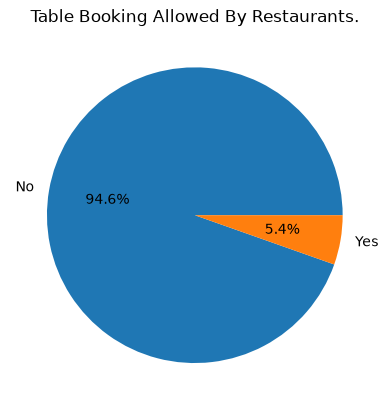

In [37]:
table_booking.plot.pie(autopct = '%1.1f%%')
plt.title('Table Booking Allowed By Restaurants.')
plt.show()

### 03. Which five restaurants have the highest number of votes?

In [38]:
df.head()

,restaurant name,online_order,book_table,rate,votes,cost,listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


In [39]:
top5_restaurants_with_highest_votes = df.nlargest(5, 'votes')
print(top5_restaurants_with_highest_votes)

      restaurant name online_order book_table  rate  votes  cost  \
38  Empire Restaurant          Yes         No   4.4   4884   750   
86      Meghana Foods          Yes         No   4.4   4401   600   
7              Onesta          Yes        Yes   4.6   2556   600   
44             Onesta          Yes        Yes   4.6   2556   600   
65        Kabab Magic          Yes         No   4.1   1720   400   

   listed_in(type)  
38           other  
86          Dining  
7            Cafes  
44           other  
65          Dining  


In [40]:
top5_restaurants_with_highest_votes

,restaurant name,online_order,book_table,rate,votes,cost,listed_in(type)
38,Empire Restaurant,Yes,No,4.4,4884,750,other
86,Meghana Foods,Yes,No,4.4,4401,600,Dining
7,Onesta,Yes,Yes,4.6,2556,600,Cafes
44,Onesta,Yes,Yes,4.6,2556,600,other
65,Kabab Magic,Yes,No,4.1,1720,400,Dining


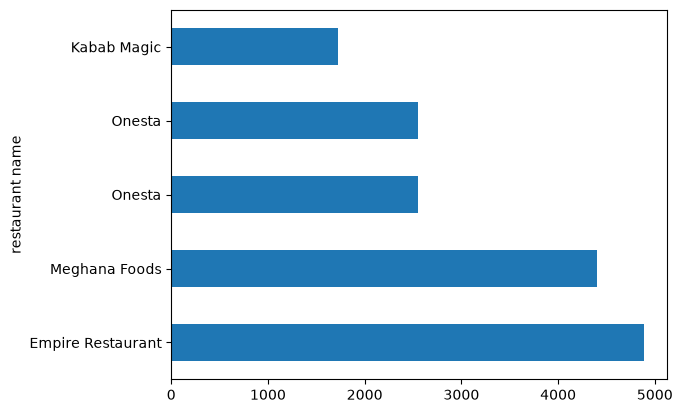

In [41]:
top5_restaurants_with_highest_votes.plot.barh(x = 'restaurant name', y = 'votes', legend = False)
plt.show()

### 04. Is there a relationship between restaurants ratings and customers votes.

In [42]:
df.head()

,restaurant name,online_order,book_table,rate,votes,cost,listed_in(type)
0,Jalsa,Yes,Yes,4.1,775,800,Buffet
1,Spice Elephant,Yes,No,4.1,787,800,Buffet
2,San Churro Cafe,Yes,No,3.8,918,800,Buffet
3,Addhuri Udupi Bhojana,No,No,3.7,88,300,Buffet
4,Grand Village,No,No,3.8,166,600,Buffet


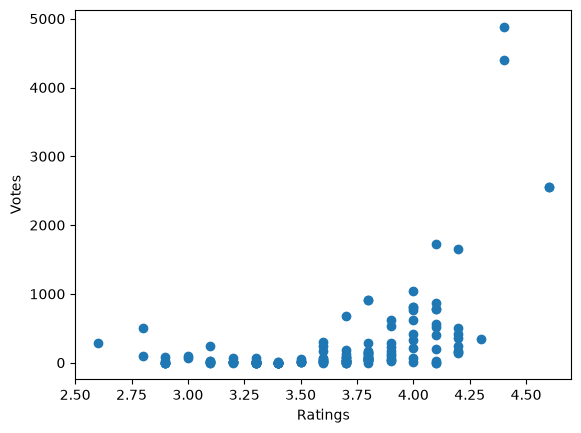

In [46]:
plt.scatter(df['rate'], df['votes'])
plt.xlabel('Ratings')
plt.ylabel('Votes')
plt.show()

In [53]:
correlation = df['rate'].corr(df['votes'])
print('Correlation:',correlation)

Correlation: 0.48984428790988815


In [48]:
covariance = df['rate'].cov(df['votes'])

In [51]:
print('Covariance: ',covariance)

Covariance:  128.8069865784152


### 05. What is the average rating for each restaurant type?